# Target smoothing & EMG compression — S02

Todo offline/no-causal.

- **Target**: Gaussiano sobre posición con distintos sigma → velocidad resultante + posición suavizada.
- **EMG**: comprimir picos respecto al baseline no-causal (Gaussiano 1s sobre RMS).

In [44]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

from dataset.preprocessing import (
    estimate_fs, causal_bandpass, causal_rms, central_diff, compute_target_velocity,
)

CSV        = '../data/raw/P01/P01_S11_20260710_150559.csv'
TOP_OFFSET = 500.0
BOT_OFFSET = 550.0
EPS        = 1e-6

df    = pd.read_csv(CSV)
t     = df['t_micros'].to_numpy(np.float64) / 1e6
fs    = estimate_fs(t)
dt    = 1.0 / fs
tasks = df['task'].to_numpy()
print(f'fs = {fs:.1f} Hz   n = {len(df):,}')


fs = 602.4 Hz   n = 456,391


In [45]:
y_top   = df['joy_ext_ind'].to_numpy()
y_bot   = df['joy_flex_ind'].to_numpy()
emg_flx = df['emg1'].to_numpy(np.float64)
emg_ext = df['emg0'].to_numpy(np.float64)

SIGMAS = [10, 50, 80]   # ms — 50 es el actual

def make_targets(sigma_ms):
    joy, vel = compute_target_velocity(
        y_top, y_bot, fs=fs, sigma_ms=sigma_ms,
        top_offset=TOP_OFFSET, bottom_offset=BOT_OFFSET)
    return joy, vel

targets = {s: make_targets(s) for s in SIGMAS}
print('Targets OK:', SIGMAS)


Targets OK: [10, 50, 80]


In [46]:
def rms_pipeline(emg_raw):
    bp       = causal_bandpass(emg_raw, fs, 70.0, 300.0)
    rms      = causal_rms(bp, fs, 40.0)
    baseline = gaussian_filter1d(rms, sigma=1.0 * fs, mode='nearest')
    return rms, baseline, rms / (baseline + EPS)

rms_flx, base_flx, norm_flx = rms_pipeline(emg_flx)
rms_ext, base_ext, norm_ext = rms_pipeline(emg_ext)

def compress(rms, baseline, alpha):
    rms_c  = baseline + np.maximum(rms - baseline, 0.0) * alpha
    base_c = gaussian_filter1d(rms_c, sigma=1.0 * fs, mode='nearest')
    return rms_c / (base_c + EPS)

ALPHAS = [0.7, 0.5]
print('EMG OK.')


EMG OK.


## 1 — Posición suavizada por sigma y task

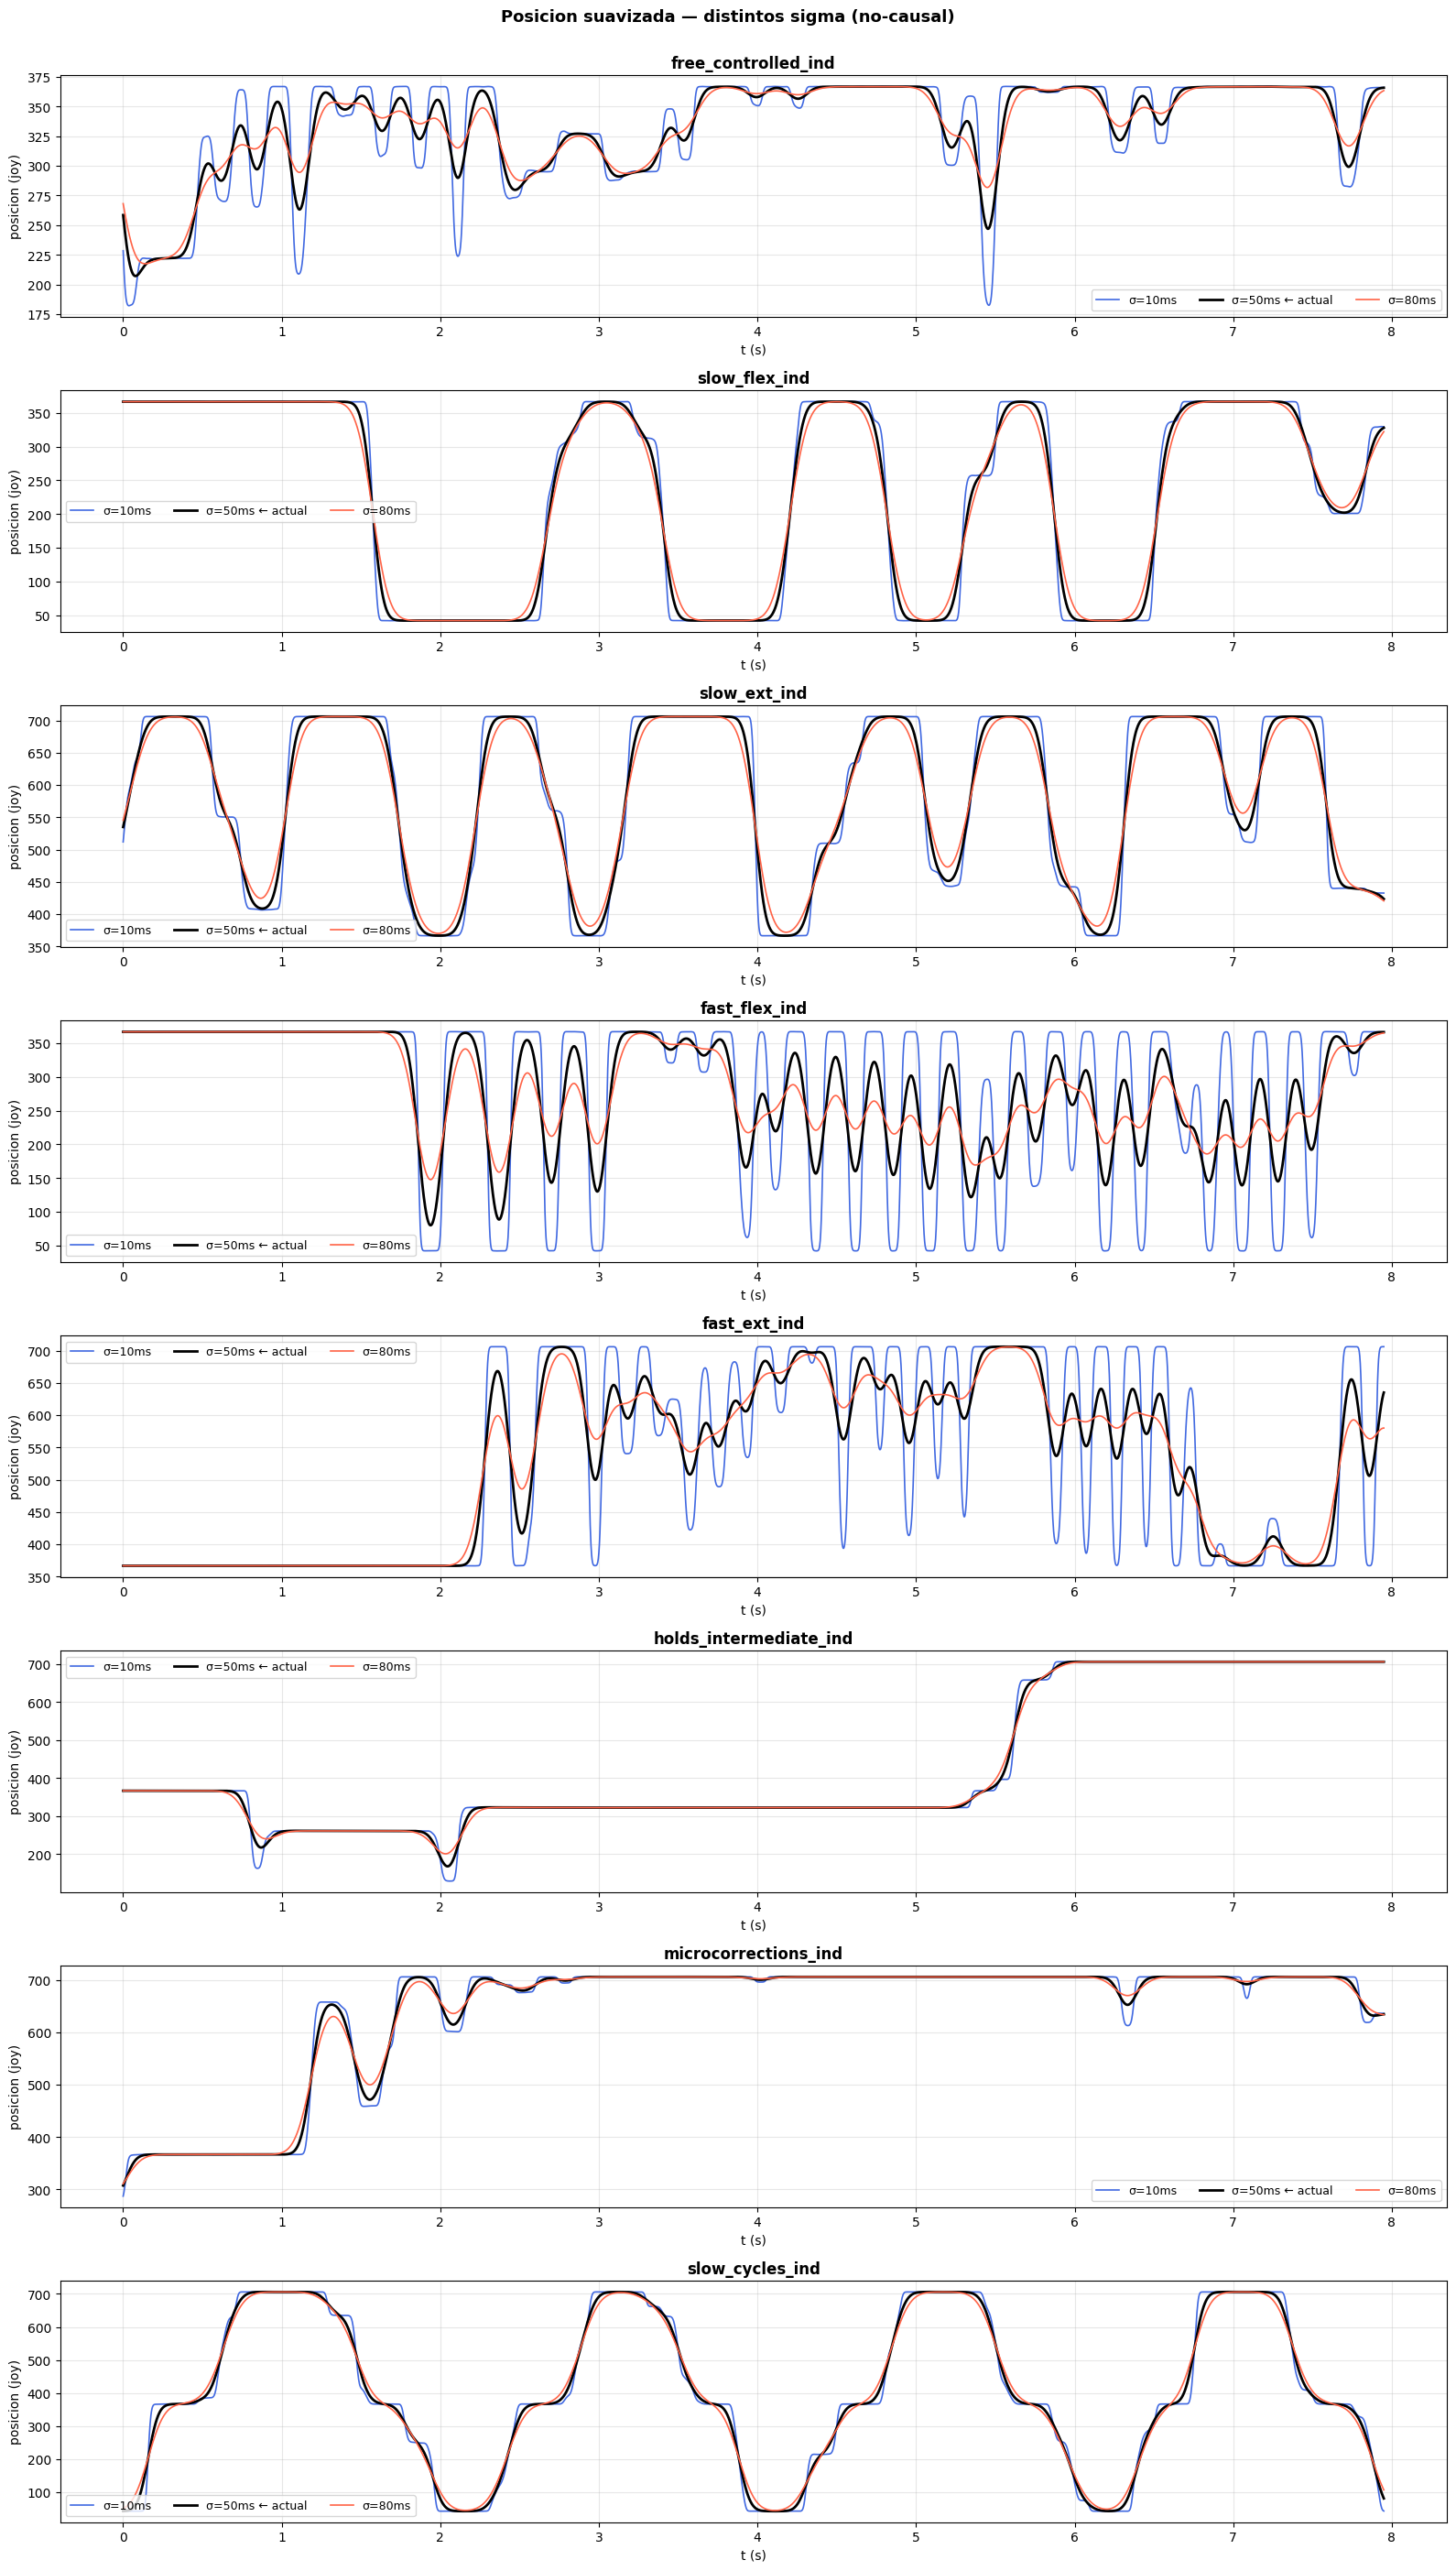

In [47]:
TASKS = [
    'free_controlled_ind', 'slow_flex_ind', 'slow_ext_ind',
    'fast_flex_ind', 'fast_ext_ind', 'holds_intermediate_ind',
    'microcorrections_ind', 'slow_cycles_ind',
]
PLOT_S = 8.0
COLORS = ['royalblue', 'black', 'tomato']   # 30 / 50(actual) / 80 ms

fig, axes = plt.subplots(len(TASKS), 1, figsize=(16, 3.5 * len(TASKS)))
for ax, task in zip(axes, TASKS):
    idx = np.where(tasks == task)[0]
    if not len(idx): ax.set_title(f'{task} — sin datos'); continue
    i0 = idx[0]; i1 = min(i0 + int(PLOT_S * fs), idx[-1] + 1)
    sl = slice(i0, i1); tr = t[sl] - t[i0]
    for s, c in zip(SIGMAS, COLORS):
        lw  = 2.0 if s == 50 else 1.2
        lab = f'σ={s}ms' + (' ← actual' if s == 50 else '')
        joy_s = targets[s][0]
        ax.plot(tr, joy_s[sl], color=c, lw=lw, label=lab)
    ax.set_title(task, fontweight='bold'); ax.set_ylabel('posicion (joy)')
    ax.set_xlabel('t (s)'); ax.legend(fontsize=9, ncol=3); ax.grid(alpha=0.3)
plt.suptitle('Posicion suavizada — distintos sigma (no-causal)', fontsize=13, fontweight='bold', y=1.001)
plt.tight_layout(); plt.show()


## 2 — Velocidad derivada por sigma y task

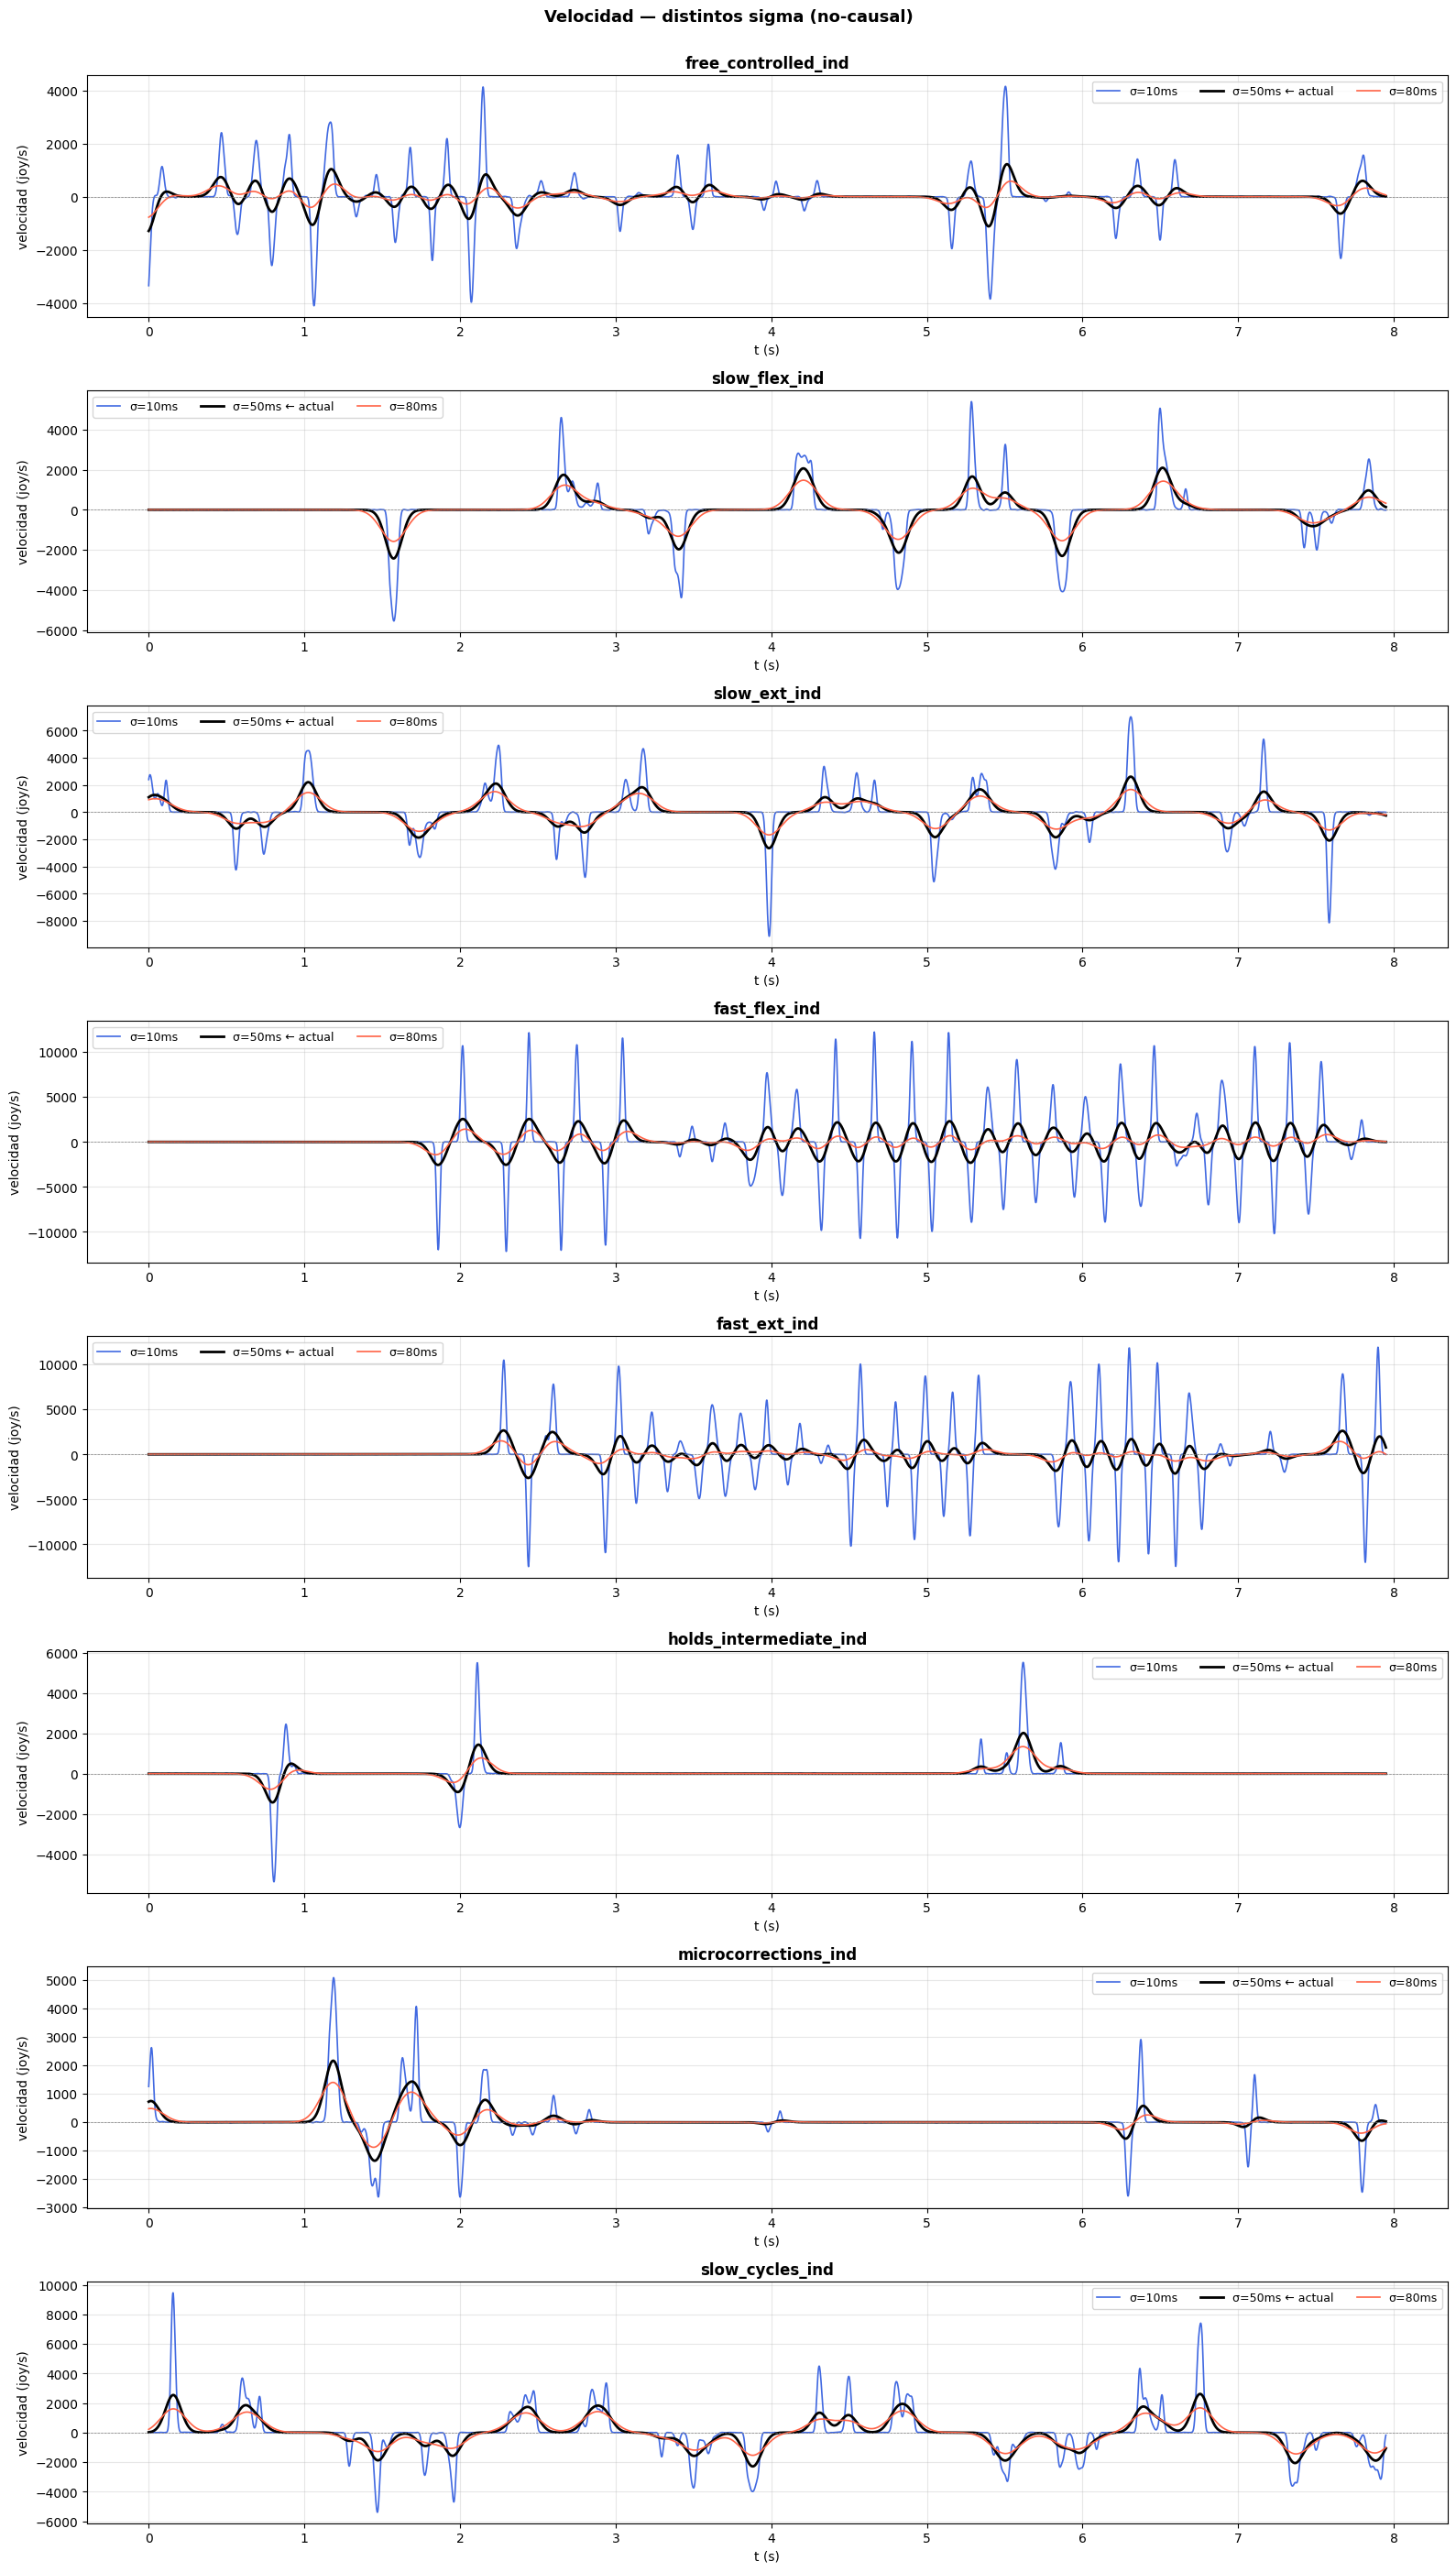

In [49]:
fig, axes = plt.subplots(len(TASKS), 1, figsize=(16, 3.5 * len(TASKS)))
for ax, task in zip(axes, TASKS):
    idx = np.where(tasks == task)[0]
    if not len(idx): ax.set_title(f'{task} — sin datos'); continue
    i0 = idx[0]; i1 = min(i0 + int(PLOT_S * fs), idx[-1] + 1)
    sl = slice(i0, i1); tr = t[sl] - t[i0]
    for s, c in zip(SIGMAS, COLORS):
        lw  = 2.0 if s == 50 else 1.2
        lab = f'σ={s}ms' + (' ← actual' if s == 50 else '')
        vel_s = targets[s][1]
        ax.plot(tr, vel_s[sl], color=c, lw=lw, label=lab)
        
    ax.axhline(0, color='gray', lw=0.5, ls='--')
    ax.set_title(task, fontweight='bold'); ax.set_ylabel('velocidad (joy/s)')
    ax.set_xlabel('t (s)'); ax.legend(fontsize=9, ncol=3); ax.grid(alpha=0.3)
plt.suptitle('Velocidad — distintos sigma (no-causal)', fontsize=13, fontweight='bold', y=1.001)
plt.tight_layout(); plt.show()


## 3 — EMG: compresion de picos por task

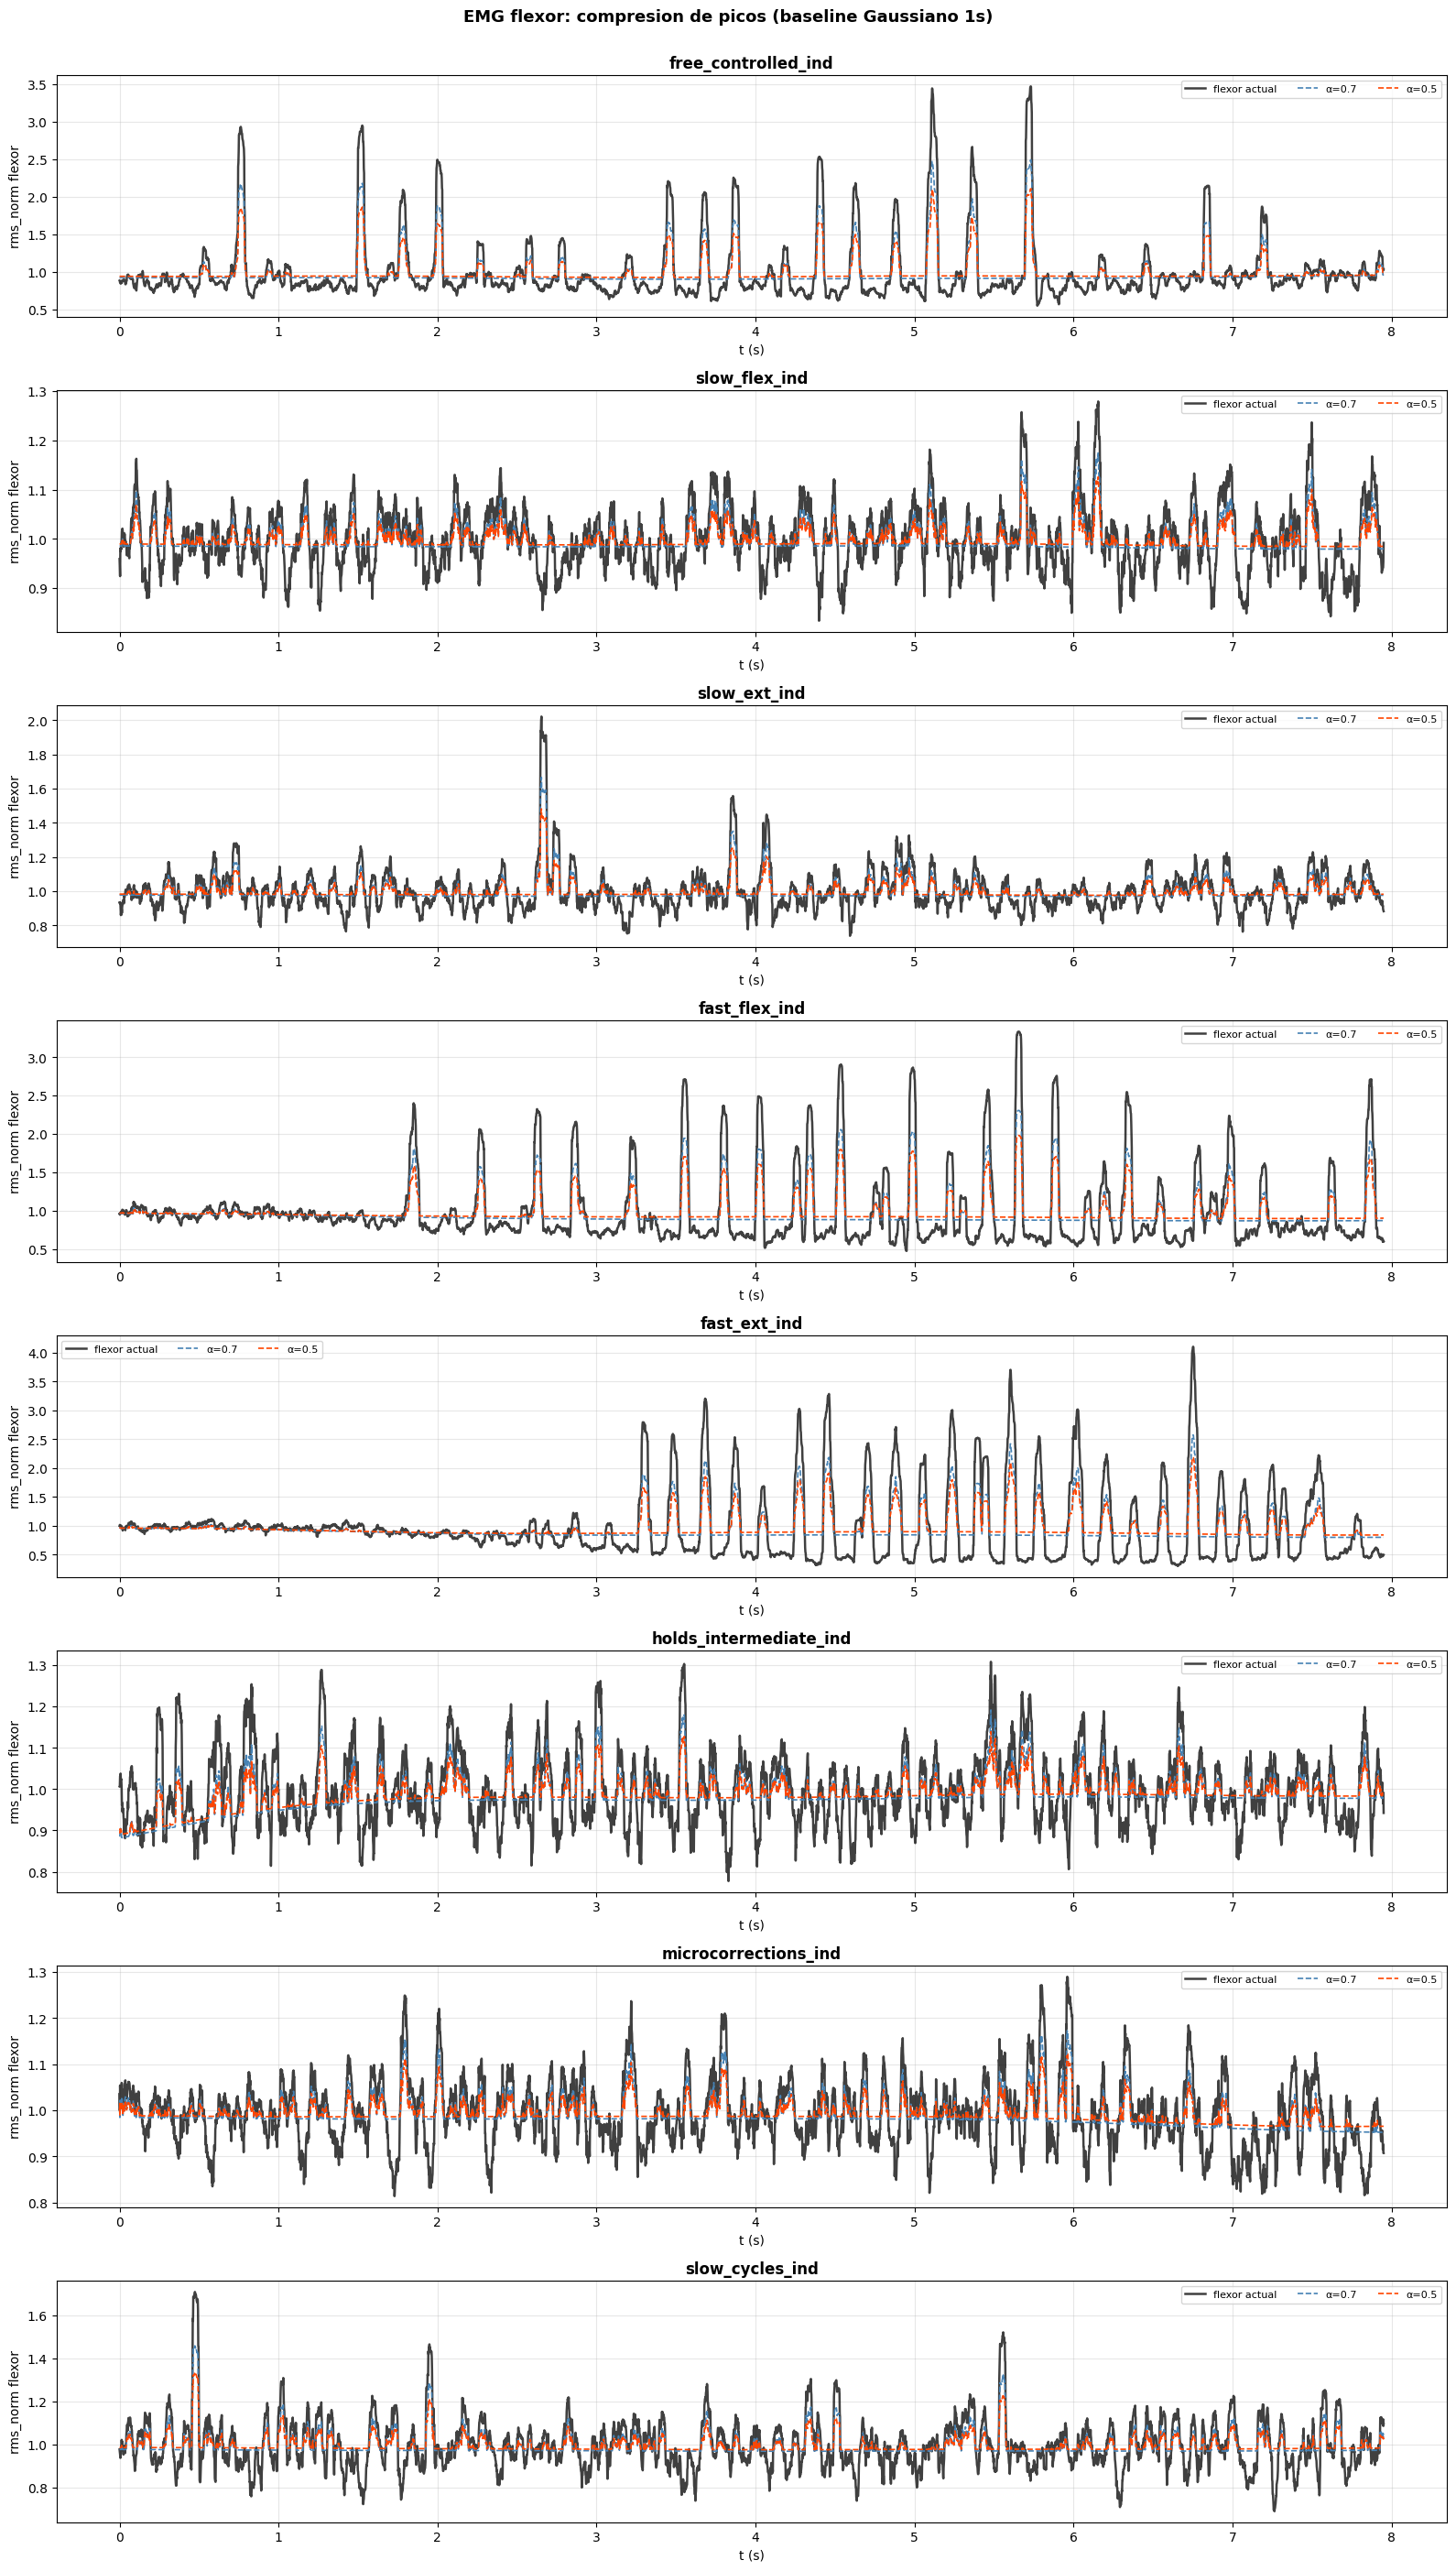

In [50]:
ACOLS = ['steelblue', 'orangered', 'purple']
fig, axes = plt.subplots(len(TASKS), 1, figsize=(16, 3.5 * len(TASKS)))
for ax, task in zip(axes, TASKS):
    idx = np.where(tasks == task)[0]
    if not len(idx): ax.set_title(f'{task} — sin datos'); continue
    i0 = idx[0]; i1 = min(i0 + int(PLOT_S * fs), idx[-1] + 1)
    sl = slice(i0, i1); tr = t[sl] - t[i0]
    ax.plot(tr, norm_flx[sl], 'k', lw=1.8, label='flexor actual', alpha=0.75)
    for alpha, c in zip(ALPHAS, ACOLS):
        ax.plot(tr, compress(rms_flx, base_flx, alpha)[sl],
                color=c, lw=1.2, ls='--', label=f'α={alpha}')
    ax.set_title(task, fontweight='bold'); ax.set_ylabel('rms_norm flexor')
    ax.set_xlabel('t (s)'); ax.legend(fontsize=8, ncol=4); ax.grid(alpha=0.3)
plt.suptitle('EMG flexor: compresion de picos (baseline Gaussiano 1s)', fontsize=13, fontweight='bold', y=1.001)
plt.tight_layout(); plt.show()


## 4 — Vista combinada con valores elegidos

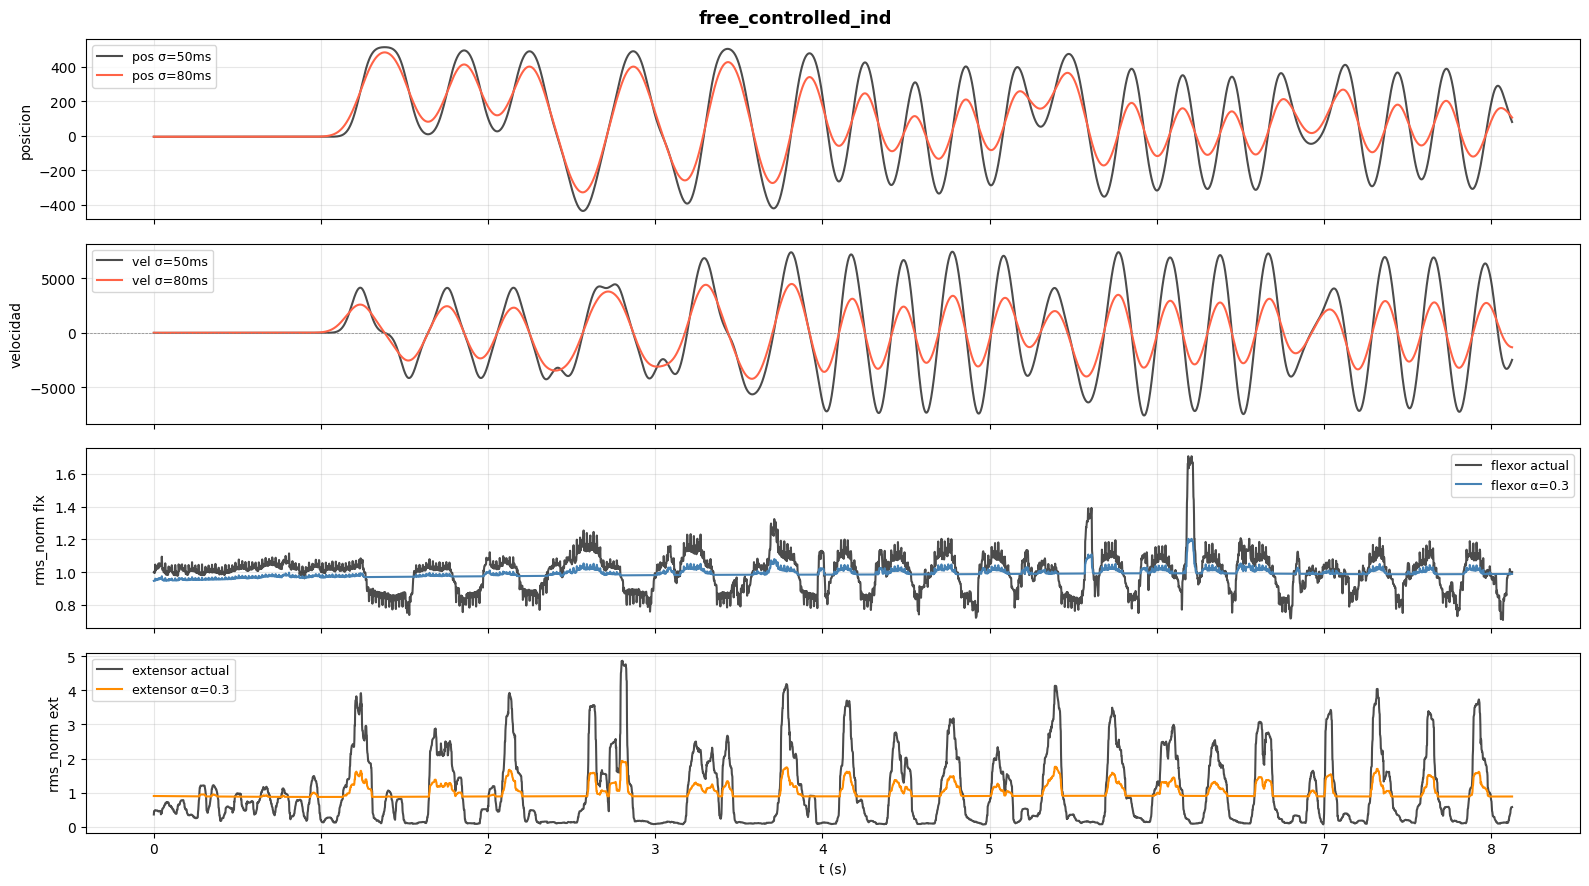

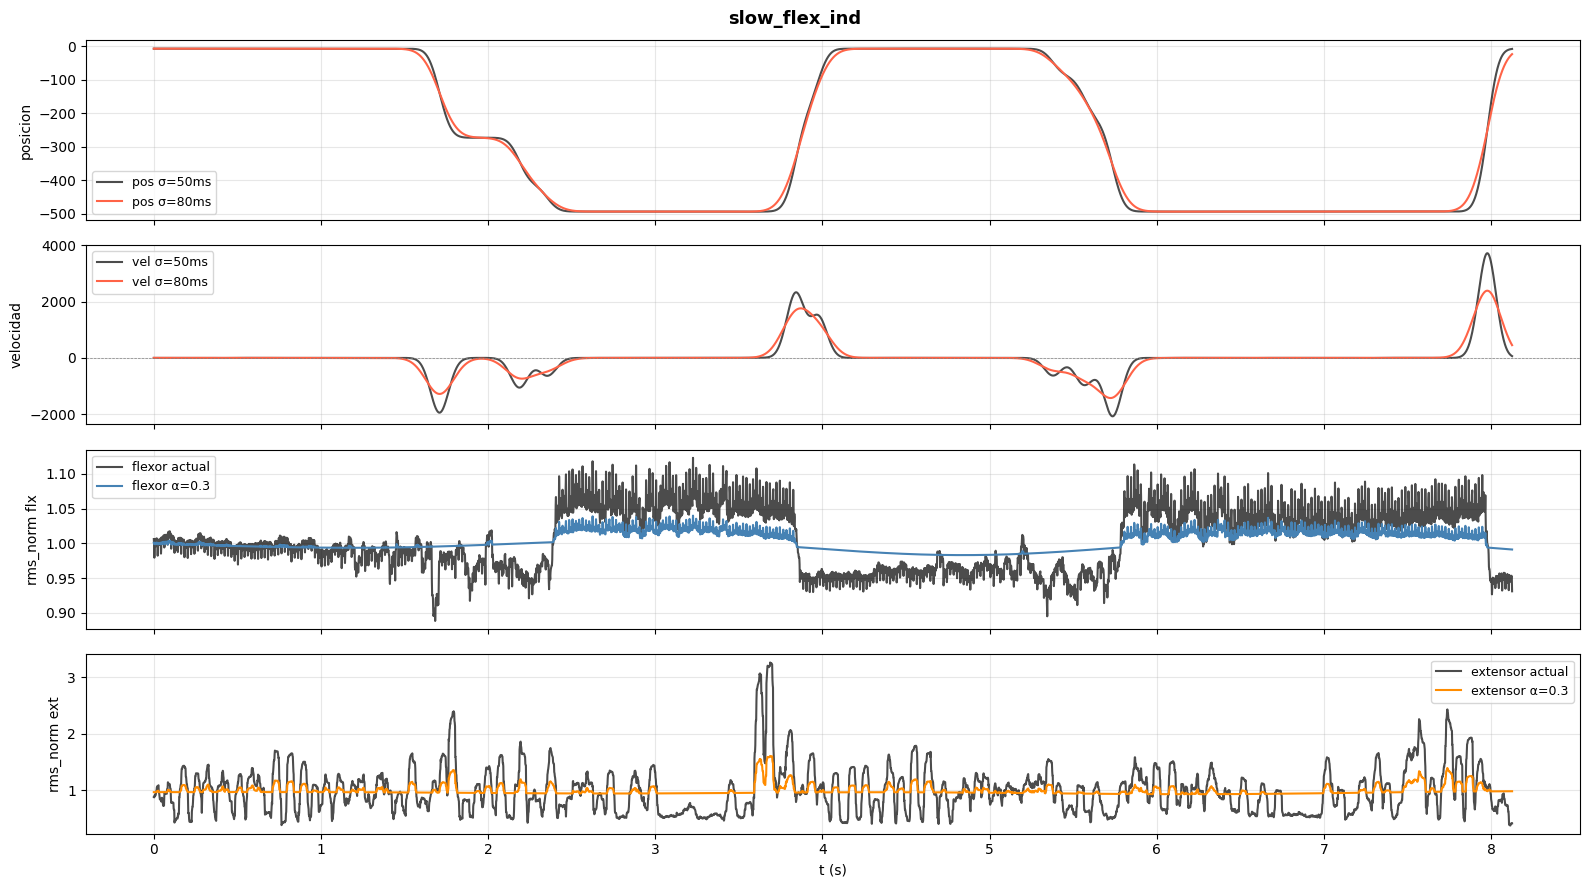

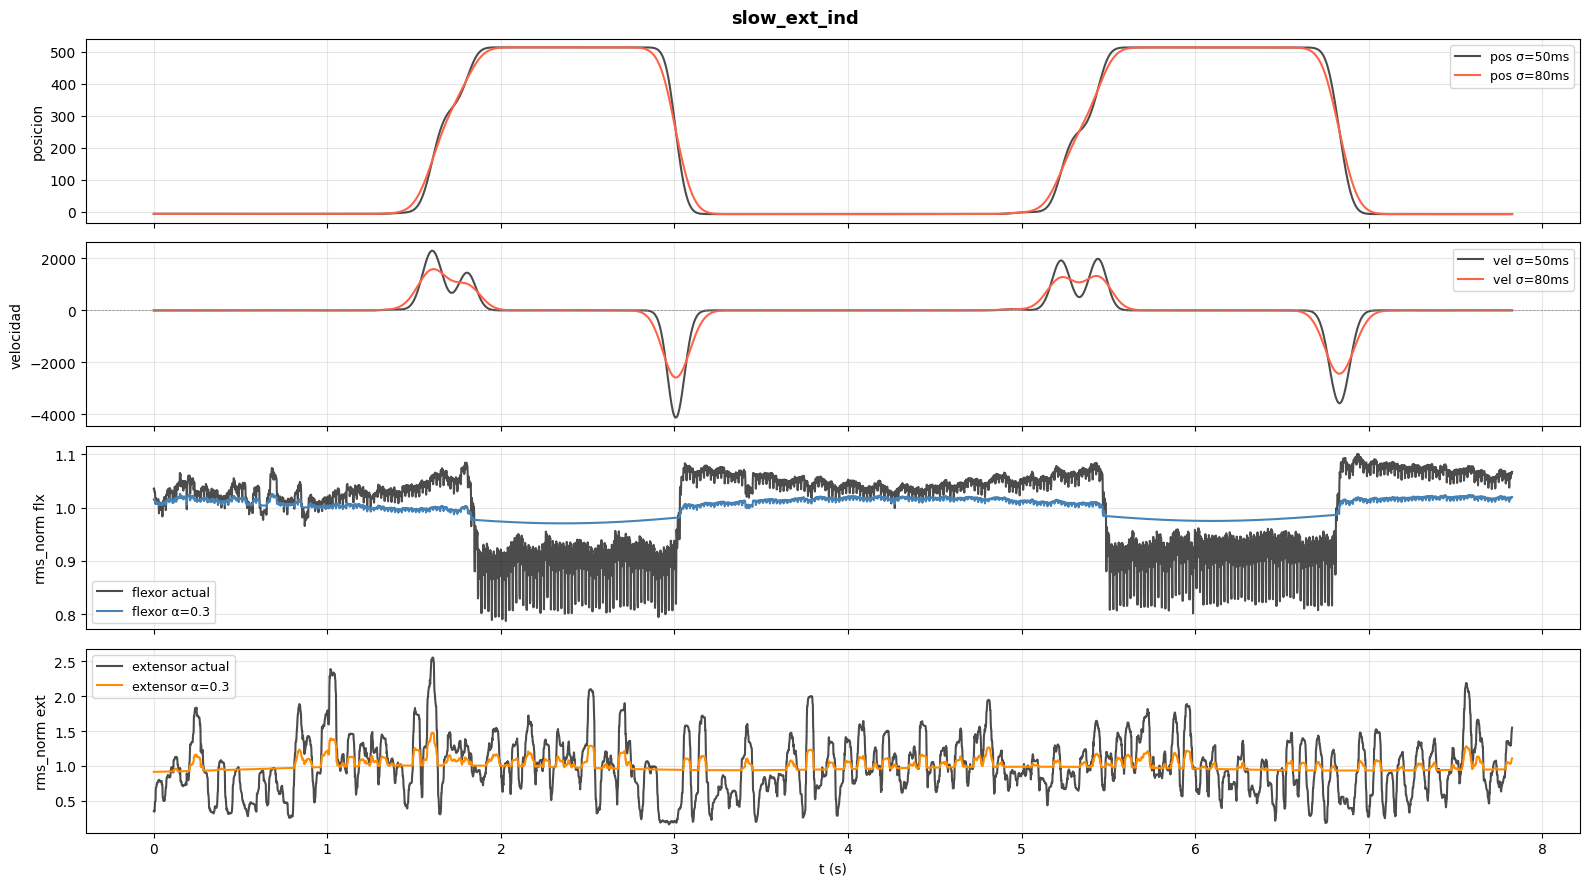

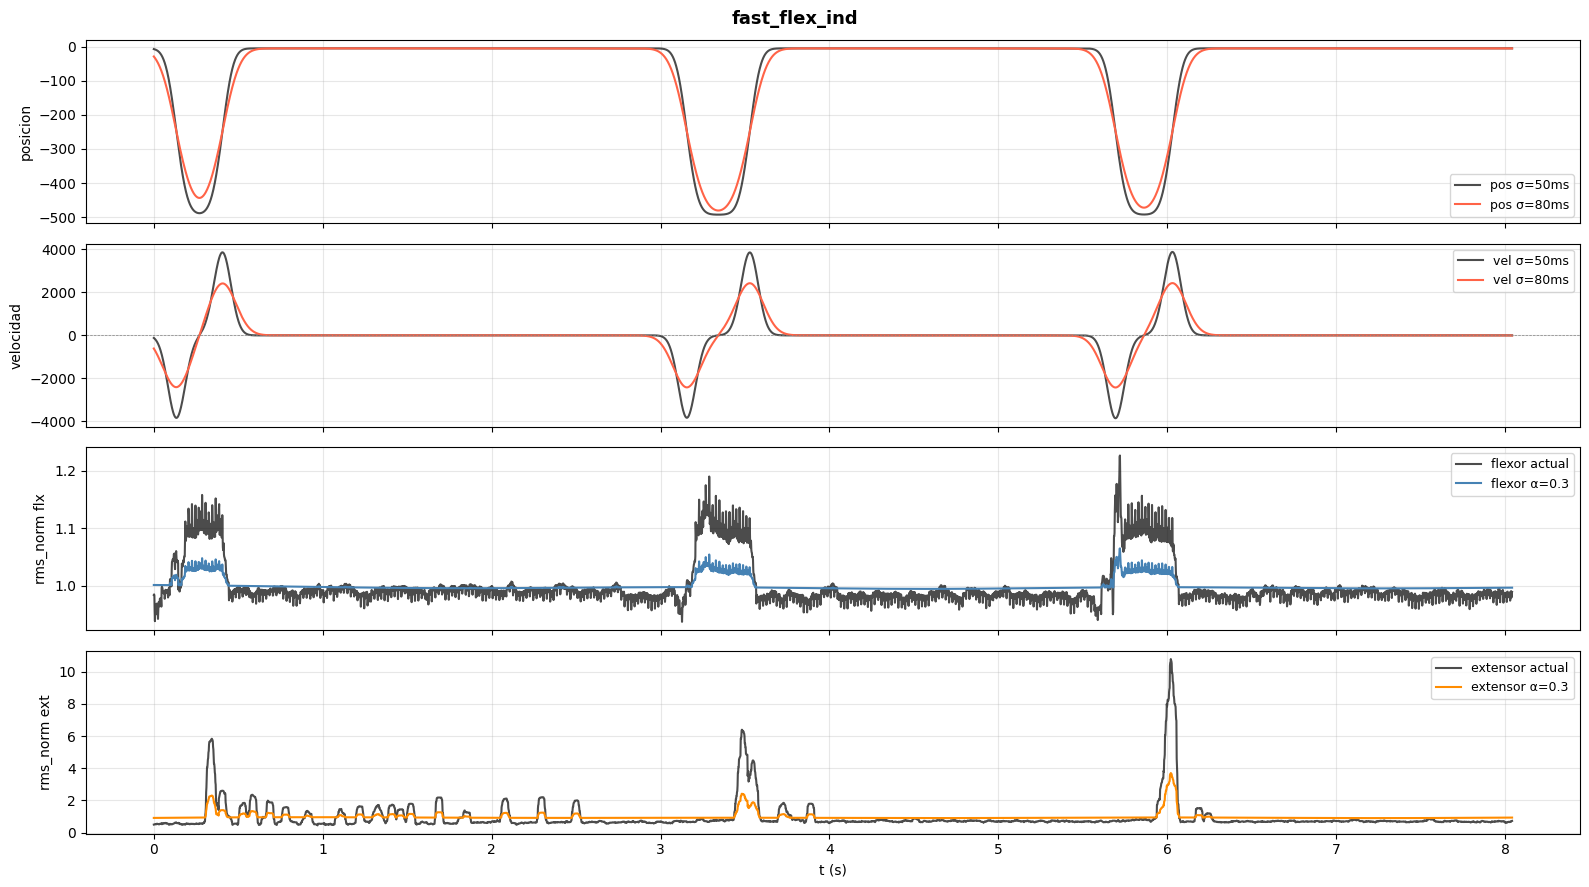

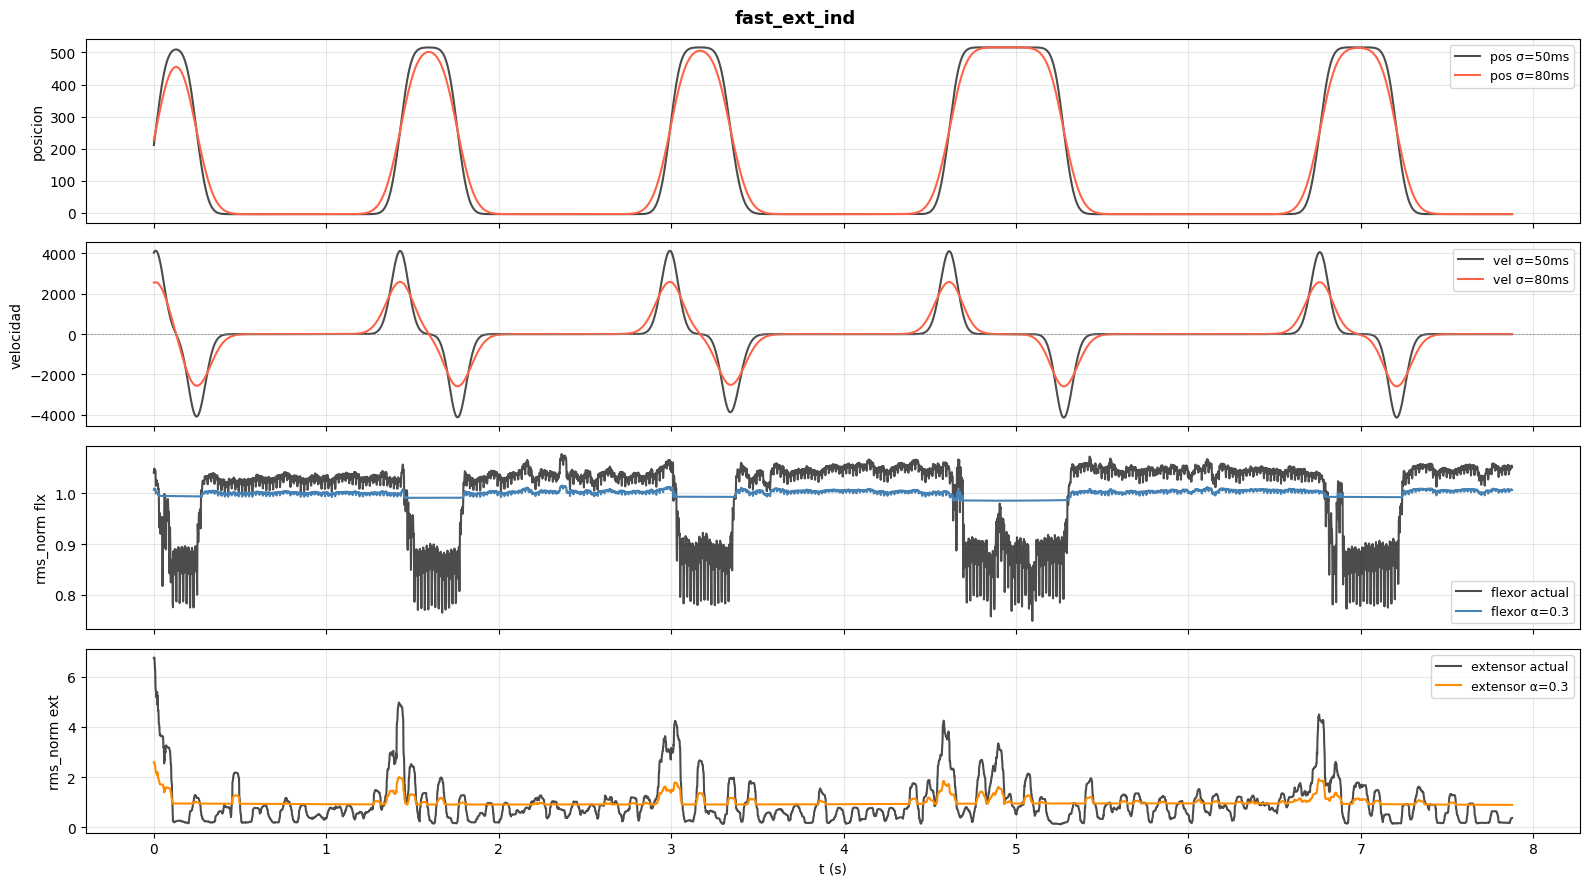

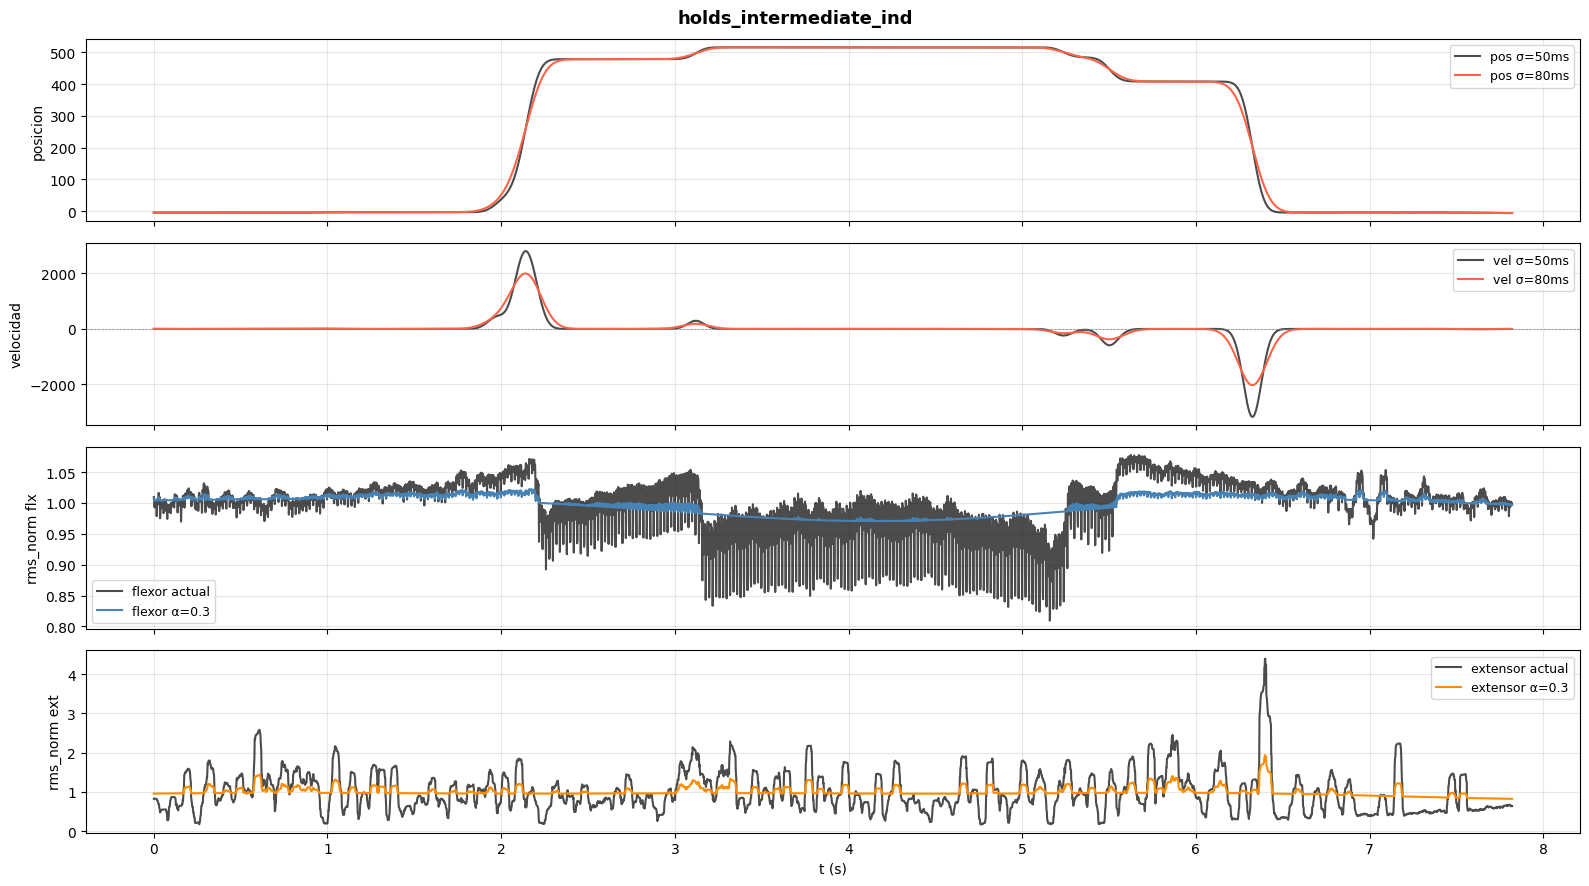

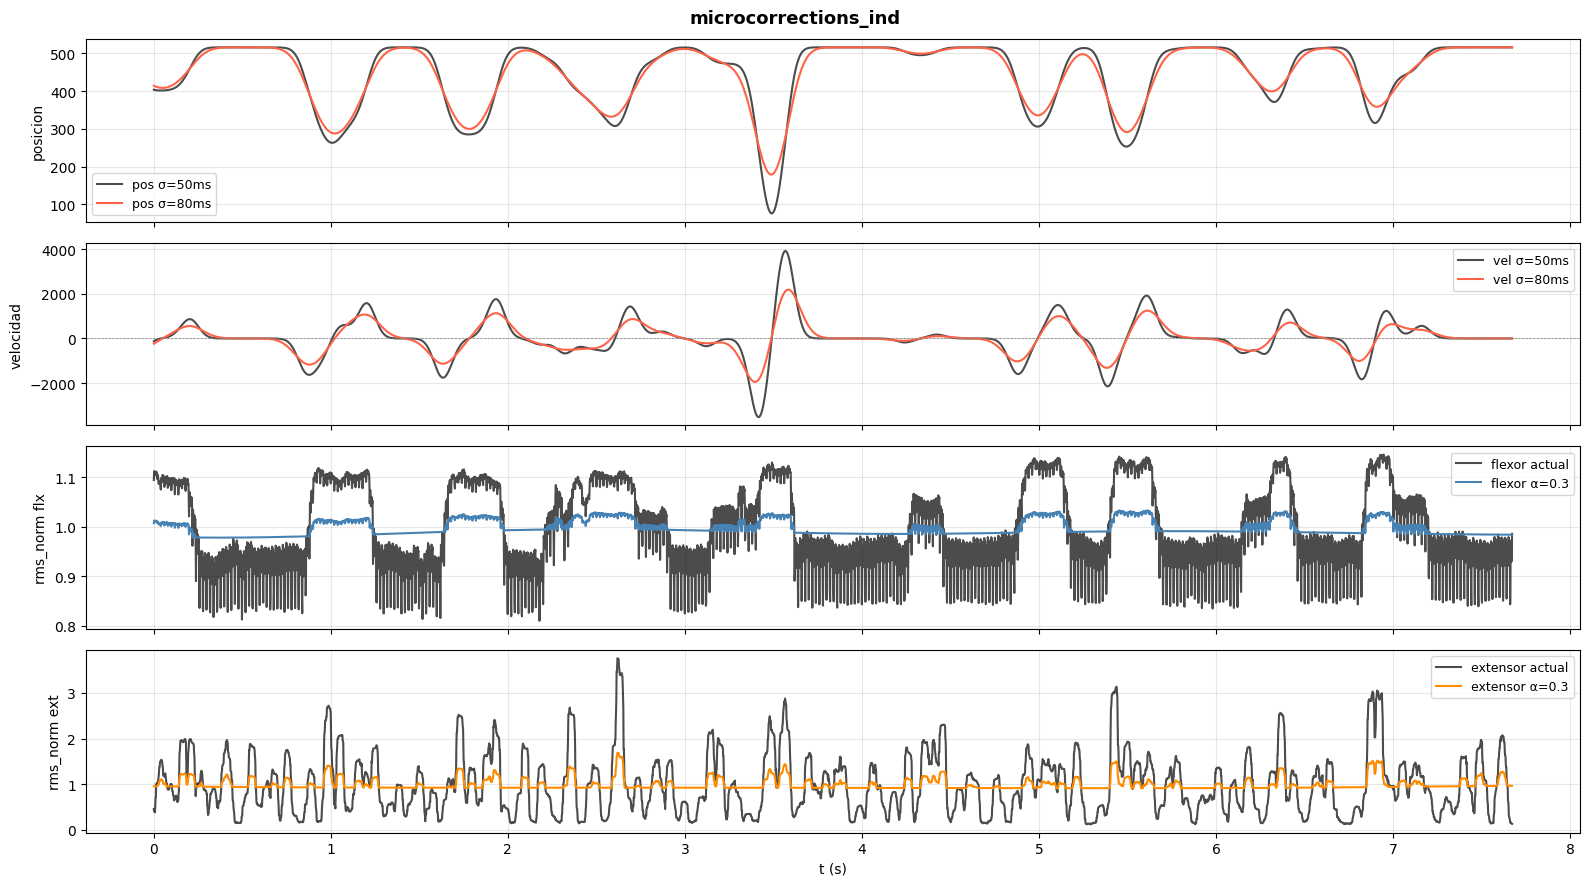

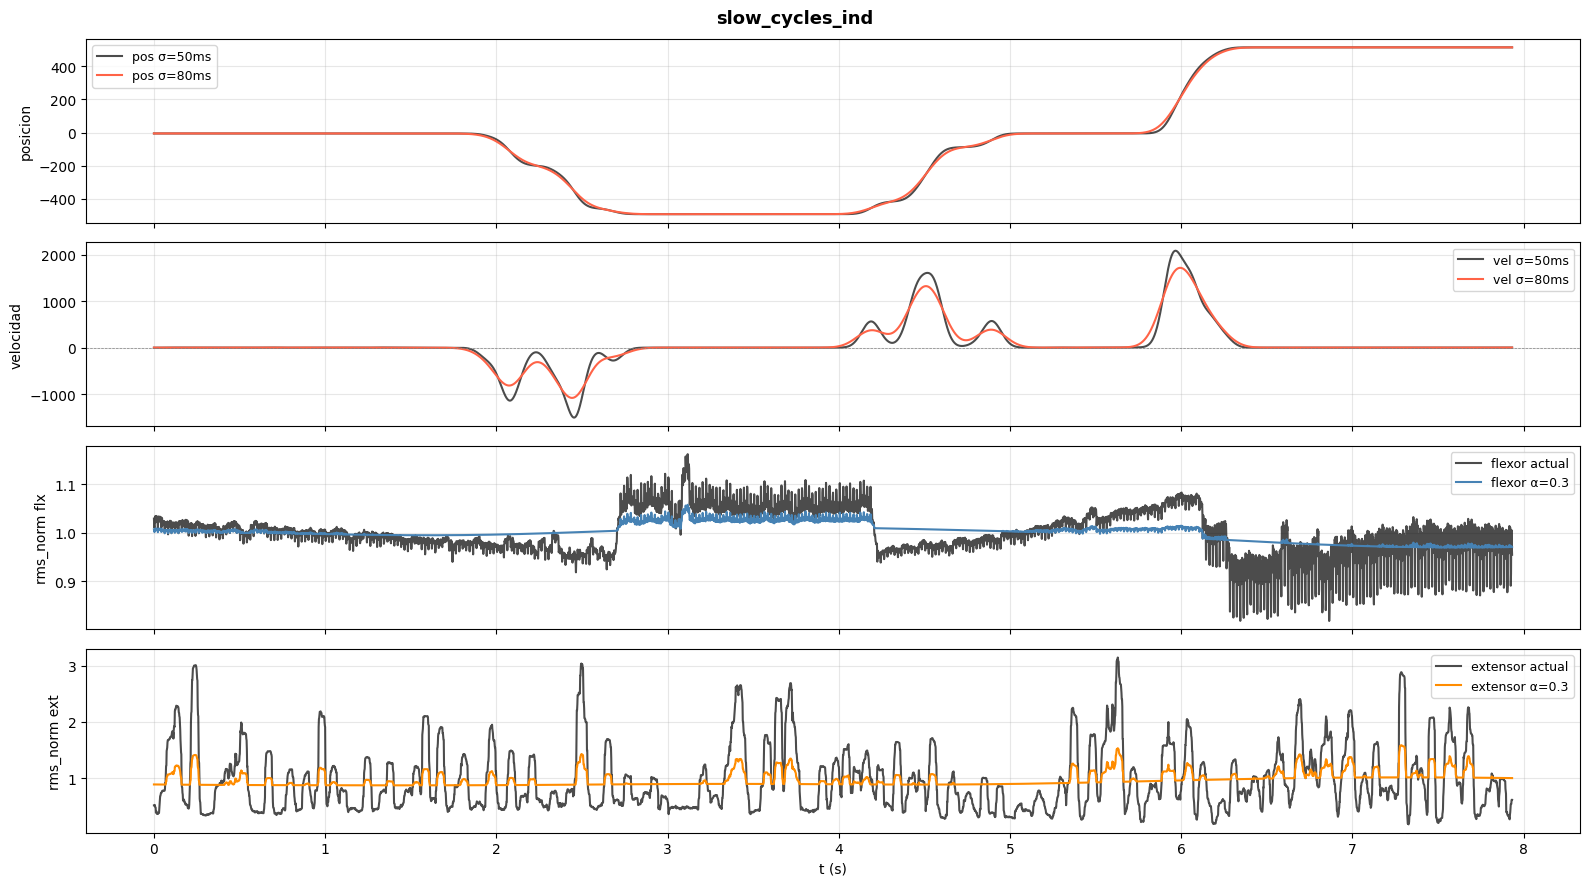

In [43]:
SIGMA_BEST = 80     # ms
ALPHA_BEST = 0.30

vel_new    = targets[SIGMA_BEST][1]
joy_new    = targets[SIGMA_BEST][0]
joy_curr   = targets[50][0]
vel_curr   = targets[50][1]
norm_flx_c = compress(rms_flx, base_flx, ALPHA_BEST)
norm_ext_c = compress(rms_ext, base_ext, ALPHA_BEST)

for task in TASKS:
    idx = np.where(tasks == task)[0]
    if not len(idx): continue
    i0 = idx[0]; i1 = min(i0 + int(PLOT_S * fs), idx[-1] + 1)
    sl = slice(i0, i1); tr = t[sl] - t[i0]

    fig, axes = plt.subplots(4, 1, figsize=(16, 9), sharex=True)
    axes[0].plot(tr, joy_curr[sl],  'k',     lw=1.5, label='pos σ=50ms', alpha=0.7)
    axes[0].plot(tr, joy_new[sl],   'tomato',lw=1.5, label=f'pos σ={SIGMA_BEST}ms')
    axes[0].set_ylabel('posicion'); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

    axes[1].plot(tr, vel_curr[sl],  'k',     lw=1.5, label='vel σ=50ms', alpha=0.7)
    axes[1].plot(tr, vel_new[sl],   'tomato',lw=1.5, label=f'vel σ={SIGMA_BEST}ms')
    axes[1].axhline(0, color='gray', lw=0.5, ls='--')
    axes[1].set_ylabel('velocidad'); axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

    axes[2].plot(tr, norm_flx[sl],   'k',         lw=1.5, label='flexor actual', alpha=0.7)
    axes[2].plot(tr, norm_flx_c[sl], 'steelblue', lw=1.5, label=f'flexor α={ALPHA_BEST}')
    axes[2].set_ylabel('rms_norm flx'); axes[2].legend(fontsize=9); axes[2].grid(alpha=0.3)

    axes[3].plot(tr, norm_ext[sl],   'k',          lw=1.5, label='extensor actual', alpha=0.7)
    axes[3].plot(tr, norm_ext_c[sl], 'darkorange', lw=1.5, label=f'extensor α={ALPHA_BEST}')
    axes[3].set_ylabel('rms_norm ext'); axes[3].set_xlabel('t (s)')
    axes[3].legend(fontsize=9); axes[3].grid(alpha=0.3)

    fig.suptitle(task, fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()
